# Bagging and Random Forests for default classification

Same setup as notebooks 02–03: **only the 80% training set**, the **same 5 stratified folds**, the shared preprocessing inside the pipeline, **F1** as the main metric, and (as in notebook 03) **no SMOTE**: imbalance is handled by tuning the cutoff. The test set stays locked.

## From one tree to a forest

**Bagging (bootstrap aggregating).** Draw $B$ bootstrap samples (rows drawn **with replacement**, same size as the training data; each contains about 63% of the distinct rows), grow one deep tree on each, and **average** their predicted probabilities. Deep trees have low bias but high variance; averaging keeps the low bias and removes much of the variance.

**Random Forest = bagging + random features.** At **every split**, each tree may only choose among a random subset of `max_features` features (e.g. √26 ≈ 5 of 26). With `max_features = None` (all features) a random forest *is* plain bagged trees.

**Why the random features help.** For $B$ trees, each with variance $\sigma^2$ and pairwise correlation $\rho$,

$$\operatorname{Var}(\text{average}) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$

More trees shrink only the second term. If every tree splits first on the same strong features (here `loan_percent_income`, renting, interest rate), the trees are highly correlated and the first term stays large. Restricting the features at each split makes the trees **less correlated** (smaller $\rho$), so averaging removes more variance.

**Out-of-bag (OOB) error.** Each tree never sees about 37% of the rows; predicting those rows with only the trees that did not see them gives a free validation estimate.

## Hyperparameters

| Hyperparameter | Effect |
|---|---|
| `n_estimators` | number of trees. More is never worse for accuracy, only slower; performance plateaus. |
| `max_features` | features tried at each split. Smaller → less correlated trees but each tree is weaker. `None` = bagging. |
| `max_depth`, `min_samples_leaf` | size of each tree (as in notebook 03). Forests usually grow deep trees and let averaging control variance. |
| `criterion` | `gini` or `entropy` |

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import (RANDOM_STATE, REPORTS, load_train, make_cv, make_pipeline,
                        f1_curve, best_cutoff, fold_metrics)

X_train, y_train = load_train()
cv = make_cv()
tree_choice = json.loads((REPORTS / "decision_tree_choice.json").read_text())["Tree"]
print("X_train:", X_train.shape, f"  default rate: {y_train.mean():.4f}")
print("best single tree from notebook 03:", tree_choice)

X_train: (25927, 11)   default rate: 0.2187
best single tree from notebook 03: {'params': {'max_depth': 10, 'min_samples_leaf': 1, 'criterion': 'entropy'}, 'cutoff': 0.6, 'cv_f1_at_cutoff': 0.8128009841403669, 'cv_f1_at_default': 0.8115407845574705, 'cv_precision_at_cutoff': 0.9706763733631923, 'cv_recall_at_cutoff': 0.6991181657848324, 'cv_roc_auc': 0.9062249524145507}


## Step 1: One tree vs. bagged trees vs. Random Forest

All scored with 5-fold CV at the default cutoff 0.5 (300 trees for the ensembles, otherwise default settings):

1. a single fully grown tree (as in notebook 03, Step 1)
2. **bagged trees** = `RandomForestClassifier(max_features=None)`: bootstrap samples, all features at every split
3. **Random Forest** = `RandomForestClassifier(max_features="sqrt")`: bootstrap samples, √26 ≈ 5 random features per split

We also measure the **average correlation between the trees' predictions** on the validation fold of round 1, which is the $\rho$ in the variance formula above.

In [2]:
variants = {
    "single full tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "bagged trees (max_features=None)": RandomForestClassifier(n_estimators=300, max_features=None,
                                                               random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest (max_features='sqrt')": RandomForestClassifier(n_estimators=300, max_features="sqrt",
                                                                  random_state=RANDOM_STATE, n_jobs=-1),
}
train_idx, val_idx = next(cv.split(X_train, y_train))
rows = []
for name, model in variants.items():
    start = time.time()
    r = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                       scoring=["precision", "recall", "f1", "roc_auc"], return_train_score=True,
                       return_estimator=True)
    row = {"model": name, "train F1": r["train_f1"].mean(), "val F1": r["test_f1"].mean(),
           "val F1 sd": r["test_f1"].std(), "val precision": r["test_precision"].mean(),
           "val recall": r["test_recall"].mean(), "val ROC-AUC": r["test_roc_auc"].mean()}
    est = r["estimator"][0]                                    # the round-1 model
    if hasattr(est.named_steps["model"], "estimators_"):
        Xv = est.named_steps["prep"].transform(X_train.iloc[val_idx])
        Xv = Xv.toarray() if hasattr(Xv, "toarray") else Xv
        P = np.array([t.predict_proba(Xv)[:, 1] for t in est.named_steps["model"].estimators_[:100]])
        C = np.corrcoef(P)
        row["avg tree correlation (rho)"] = C[np.triu_indices_from(C, k=1)].mean()
    row["seconds"] = round(time.time() - start)
    rows.append(row)
step1 = pd.DataFrame(rows).set_index("model")
display(step1.round(4))

,train F1,val F1,val F1 sd,val precision,val recall,val ROC-AUC,seconds,avg tree correlation (rho)
model,,,,,,,,
single full tree,1.0,0.7457,0.0038,0.7336,0.7584,0.8406,2,NaN
bagged trees (max_features=None),1.0,0.8236,0.0036,0.9556,0.7236,0.9323,30,0.6391
Random Forest (max_features='sqrt'),1.0,0.8218,0.0042,0.9647,0.7159,0.9307,18,0.5695


## Step 2: How many trees?

Validation F1 (5-fold CV) and **out-of-bag** F1 as the number of trees grows, for bagged trees and the Random Forest. OOB F1 is computed on the full training set using, for each row, only the trees that did not see it.

val F1                            OOB F1             
model Random Forest (sqrt) bagged trees Random Forest (sqrt) bagged trees
trees                                                                    
1                   0.7059       0.7307                  NaN          NaN
10                  0.8099       0.8136                  NaN          NaN
50                  0.8201       0.8216               0.8167       0.8216
100                 0.8209       0.8228               0.8210       0.8279
200                 0.8223       0.8233               0.8230       0.8271
400                 0.8216       0.8234               0.8231       0.8276

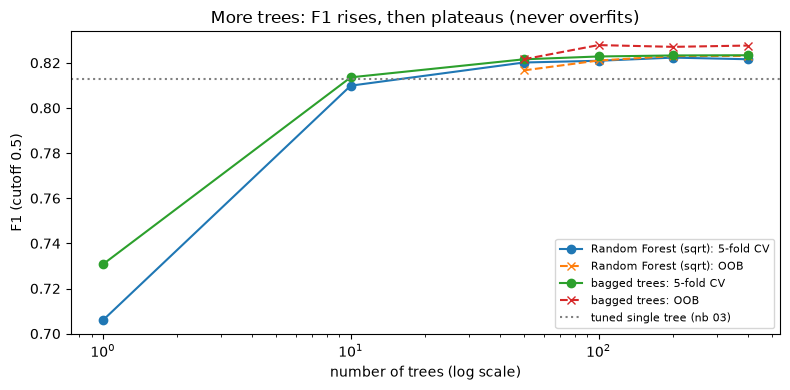

In [3]:
n_trees = [1, 10, 50, 100, 200, 400]
curve_rows = []
for label, mf in [("bagged trees", None), ("Random Forest (sqrt)", "sqrt")]:
    for n in n_trees:
        rf = RandomForestClassifier(n_estimators=n, max_features=mf, random_state=RANDOM_STATE, n_jobs=-1)
        r = cross_validate(make_pipeline(rf), X_train, y_train, cv=cv, scoring="f1")
        row = {"model": label, "trees": n, "val F1": r["test_score"].mean()}
        if n >= 50:   # OOB needs enough trees for every row to be out-of-bag at least once
            oob = make_pipeline(RandomForestClassifier(n_estimators=n, max_features=mf, oob_score=True,
                                                       random_state=RANDOM_STATE, n_jobs=-1)).fit(X_train, y_train)
            p_oob = oob.named_steps["model"].oob_decision_function_[:, 1]
            row["OOB F1"] = f1_score(y_train, (p_oob >= 0.5).astype(int))
        curve_rows.append(row)
trees_curve = pd.DataFrame(curve_rows)
display(trees_curve.pivot(index="trees", columns="model", values=["val F1", "OOB F1"]).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
for label, g in trees_curve.groupby("model"):
    ax.plot(g["trees"], g["val F1"], marker="o", label=f"{label}: 5-fold CV")
    ax.plot(g["trees"], g["OOB F1"], marker="x", linestyle="--", label=f"{label}: OOB")
ax.axhline(tree_choice["cv_f1_at_cutoff"], color="grey", linestyle=":", label="tuned single tree (nb 03)")
ax.set_xscale("log"); ax.set_xlabel("number of trees (log scale)"); ax.set_ylabel("F1 (cutoff 0.5)")
ax.set_title("More trees: F1 rises, then plateaus (never overfits)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Step 3: Tuning the Random Forest

`RandomizedSearchCV` tries **15 random combinations** from the grid below (the full grid has 4 × 3 × 4 × 2 = 96), each scored with 5-fold CV; best = highest **mean validation F1** at cutoff 0.5. `n_estimators` is fixed at 300 because Step 2 shows F1 has plateaued by then. `max_features = None` is in the grid, so plain bagging competes too.

In [4]:
rf_space = {"model__max_depth": [None, 12, 20, 30],
            "model__min_samples_leaf": [1, 2, 5],
            "model__max_features": ["sqrt", 0.3, 0.5, None],
            "model__criterion": ["gini", "entropy"]}
rs = RandomizedSearchCV(make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
                        rf_space, n_iter=15, cv=cv, scoring="f1", n_jobs=-1, random_state=RANDOM_STATE)
start = time.time()
rs.fit(X_train, y_train)
rf_res = (pd.DataFrame(rs.cv_results_)
            .rename(columns={c: c.replace("param_model__", "") for c in rs.cv_results_ if c.startswith("param_")})
            .rename(columns={"mean_test_score": "mean F1", "std_test_score": "sd F1"})
            [["max_depth", "min_samples_leaf", "max_features", "criterion", "mean F1", "sd F1", "rank_test_score"]]
            .sort_values("rank_test_score"))
print(f"15 combinations x 5 folds in {time.time() - start:.0f}s. Top 5 by mean validation F1:")
display(rf_res.head(5).round(4))

def to_params(row):
    mf, md_ = row["max_features"], row["max_depth"]
    return {"max_depth": None if md_ is None or pd.isna(md_) else int(md_),
            "min_samples_leaf": int(row["min_samples_leaf"]), "criterion": row["criterion"],
            "max_features": None if mf is None or (isinstance(mf, float) and np.isnan(mf)) else mf}
rf_params = to_params(rf_res.iloc[0])
print("chosen:", rf_params)

15 combinations x 5 folds in 355s. Top 5 by mean validation F1:


,max_depth,min_samples_leaf,max_features,criterion,mean F1,sd F1,rank_test_score
7,30,1,0.5,gini,0.8284,0.0030,1
11,20,1,0.5,gini,0.8247,0.0035,2
14,20,2,0.5,gini,0.8232,0.0043,3
4,20,1,None,gini,0.8221,0.0041,4
8,None,1,sqrt,gini,0.8218,0.0042,5


chosen: {'max_depth': 30, 'min_samples_leaf': 1, 'criterion': 'gini', 'max_features': 0.5}


## Step 4: Cutoff tuning (exact search)

With the chosen settings fixed: **out-of-fold probabilities**, then every distinct probability is tried as the cutoff and the highest F1 kept, with the per-fold check. A forest's probability is the **average of 300 trees**, so it has many more distinct values than a single tree and the curve is much smoother.

best cutoff 0.453  (each fold's own best: [0.437, 0.46, 0.463, 0.42, 0.51])
F1 at 0.5 = 0.8288  ->  F1 at 0.453 = 0.8298;  tuned cutoff beats 0.5 in 4 of 5 rounds


,accuracy,precision,recall,f1,roc_auc
round,,,,,
1,0.9346,0.9638,0.7284,0.8297,0.9397
2,0.9368,0.9600,0.7416,0.8368,0.9321
3,0.9335,0.9428,0.7407,0.8296,0.9326
4,0.9329,0.9538,0.7284,0.8260,0.9332
5,0.9333,0.9560,0.7284,0.8268,0.9336
mean,0.9342,0.9553,0.7335,0.8298,0.9342
sd,0.0016,0.0080,0.0070,0.0043,0.0031


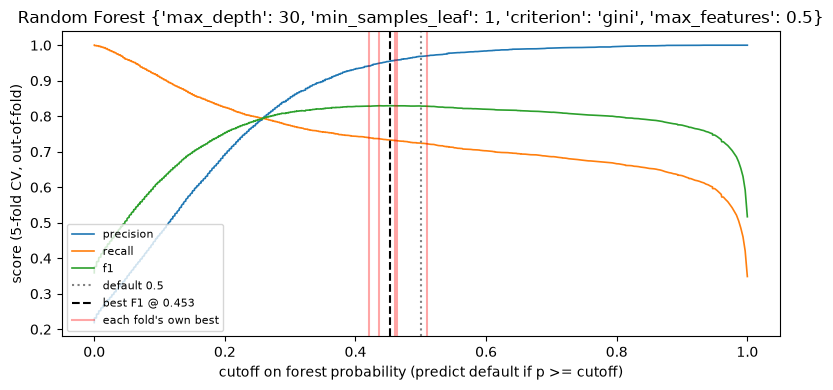

In [5]:
pipe = make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **rf_params))
p = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
cut = best_cutoff(p, y_train)
at05, atb = fold_metrics(p, y_train, 0.5, X_train, cv), fold_metrics(p, y_train, cut, X_train, cv)
own = [best_cutoff(p[v], y_train.iloc[v]) for _, v in cv.split(X_train, y_train)]
beats = sum(f1_score(y_train.iloc[v], (p[v] >= cut).astype(int)) > f1_score(y_train.iloc[v], (p[v] >= 0.5).astype(int))
            for _, v in cv.split(X_train, y_train))
print(f"best cutoff {cut:.3f}  (each fold's own best: {np.round(own, 3).tolist()})")
print(f"F1 at 0.5 = {at05.loc['mean', 'f1']:.4f}  ->  F1 at {cut:.3f} = {atb.loc['mean', 'f1']:.4f};  "
      f"tuned cutoff beats 0.5 in {beats} of 5 rounds")
display(atb.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
f1_curve(p, y_train).plot(ax=ax, linewidth=1.2)
ax.axvline(0.5, color="grey", linestyle=":", label="default 0.5")
ax.axvline(cut, color="black", linestyle="--", label=f"best F1 @ {cut:.3f}")
for i, c in enumerate(own):
    ax.axvline(c, color="red", alpha=0.35, label="each fold's own best" if i == 0 else None)
ax.set_xlabel("cutoff on forest probability (predict default if p >= cutoff)")
ax.set_ylabel("score (5-fold CV, out-of-fold)"); ax.set_title(f"Random Forest {rf_params}")
ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

## Step 5: Which features matter? (permutation importance)

Impurity importance (used in notebook 03) is biased toward features with many split points. **Permutation importance** is more reliable: take the round-1 model, shuffle one original column at a time in its **validation fold** (data the model never saw), and measure how much ROC-AUC drops. A big drop means the model relies on that feature. Repeated 5 times per feature.

,mean drop in ROC-AUC,sd
loan_percent_income,0.0853,0.0022
person_home_ownership,0.0708,0.0021
person_income,0.0689,0.0051
loan_grade,0.0567,0.0030
loan_intent,0.0459,0.0007
loan_int_rate,0.0307,0.0013
person_emp_length,0.0143,0.0019
loan_amnt,0.0085,0.0012
person_age,0.0078,0.0019
cb_person_default_on_file,0.0070,0.0007


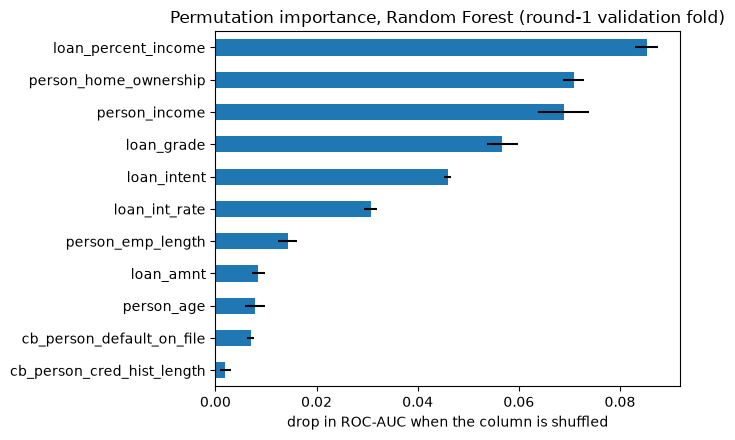

In [6]:
pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
pi = permutation_importance(pipe, X_train.iloc[val_idx], y_train.iloc[val_idx], scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"mean drop in ROC-AUC": pi.importances_mean, "sd": pi.importances_std},
                   index=X_train.columns).sort_values("mean drop in ROC-AUC")
display(imp.iloc[::-1].round(4))
imp["mean drop in ROC-AUC"].plot.barh(xerr=imp["sd"], figsize=(7, 4.5),
                                      title="Permutation importance, Random Forest (round-1 validation fold)")
plt.xlabel("drop in ROC-AUC when the column is shuffled"); plt.tight_layout(); plt.show()

## Step 6: Leaderboard and saved choice

All models at their own tuned cutoff (5-fold CV, training set). Rows from notebooks 02 and 03 are copied from their leaderboards. The forest settings and cutoff are saved to `reports/random_forest_choice.json` for the probability-of-default notebook.

In [7]:
earlier = pd.DataFrame([
    {"model": "Tree, " + ", ".join(f"{k}={v}" for k, v in tree_choice["params"].items()),
     "F1 @ default": tree_choice["cv_f1_at_default"], "best cutoff": round(tree_choice["cutoff"], 3),
     "precision @ best": tree_choice["cv_precision_at_cutoff"], "recall @ best": tree_choice["cv_recall_at_cutoff"],
     "F1 @ best": tree_choice["cv_f1_at_cutoff"], "roc_auc": tree_choice["cv_roc_auc"]},
    {"model": "SVM RBF (no SMOTE), C=100, gamma=0.03", "F1 @ default": 0.7824, "best cutoff": -0.143,
     "precision @ best": 0.9084, "recall @ best": 0.6905, "F1 @ best": 0.7845, "roc_auc": 0.9058},
    {"model": "SVM RBF + SMOTE, C=30, gamma=0.03", "F1 @ default": 0.7573, "best cutoff": 0.397,
     "precision @ best": 0.8683, "recall @ best": 0.6963, "F1 @ best": 0.7728, "roc_auc": 0.9080},
    {"model": "LogReg (no SMOTE)", "F1 @ default": 0.6463, "best cutoff": 0.330,
     "precision @ best": 0.6543, "recall @ best": 0.6996, "F1 @ best": 0.6762, "roc_auc": 0.8688},
]).set_index("model")
rf_label = "Random Forest, " + ", ".join(f"{k}={v}" for k, v in rf_params.items())
rf_row = pd.DataFrame([{"model": rf_label, "F1 @ default": at05.loc["mean", "f1"], "best cutoff": round(cut, 3),
                        "precision @ best": atb.loc["mean", "precision"], "recall @ best": atb.loc["mean", "recall"],
                        "F1 @ best": atb.loc["mean", "f1"], "roc_auc": at05.loc["mean", "roc_auc"]}]).set_index("model")
board = pd.concat([rf_row, earlier]).sort_values("F1 @ best", ascending=False)
print("Leaderboard (5-fold CV on the training set, each model at its own tuned cutoff):")
display(board.round(4))

choice = {"Random Forest": {"params": rf_params, "n_estimators": 300, "cutoff": cut,
                            "cv_f1_at_cutoff": float(atb.loc["mean", "f1"])}}
(REPORTS / "random_forest_choice.json").write_text(json.dumps(choice, indent=2))
print("saved reports/random_forest_choice.json:\n", json.dumps(choice, indent=2))

Leaderboard (5-fold CV on the training set, each model at its own tuned cutoff):


,F1 @ default,best cutoff,precision @ best,recall @ best,F1 @ best,roc_auc
model,,,,,,
"Random Forest, max_depth=30, min_samples_leaf=1, criterion=gini, max_features=0.5",0.8288,0.453,0.9553,0.7335,0.8298,0.9342
"Tree, max_depth=10, min_samples_leaf=1, criterion=entropy",0.8115,0.600,0.9707,0.6991,0.8128,0.9062
"SVM RBF (no SMOTE), C=100, gamma=0.03",0.7824,-0.143,0.9084,0.6905,0.7845,0.9058
"SVM RBF + SMOTE, C=30, gamma=0.03",0.7573,0.397,0.8683,0.6963,0.7728,0.9080
LogReg (no SMOTE),0.6463,0.330,0.6543,0.6996,0.6762,0.8688


saved reports/random_forest_choice.json:
 {
  "Random Forest": {
    "params": {
      "max_depth": 30,
      "min_samples_leaf": 1,
      "criterion": "gini",
      "max_features": 0.5
    },
    "n_estimators": 300,
    "cutoff": 0.45290000263428254,
    "cv_f1_at_cutoff": 0.8298012357927919
  }
}
